# When Outliers Matter: Investigating Gradient-Based Data Selection for Robust Learning

**UCLA CS 260D — Final Project | Fall 2026**

## 2. Experiment 1: Empirical Risk Minimization (ERM) Baseline

### 2.1 Introduction

Empirical Risk Minimization (ERM) is the standard approach to supervised machine learning, where a model is trained to minimize the average loss over all training examples.

However, when the training dataset contains strong spurious correlations, ERM may learn features that are highly predictive during training but unrelated to the true classification task.

In SpuCoMNIST, handwritten digit classes are strongly correlated with background colors. Although the actual task is to classify the digits, a model may exploit the background color as a shortcut.

### 2.2 Experiment Objective

The objective of this experiment is to establish a baseline for evaluating the robustness of standard CNN training under spurious correlations.

Specifically, we aim to:

1. Train a small Convolutional Neural Network (CNN) using standard ERM.
2. Evaluate classification accuracy across all four majority and minority groups.
3. Compare overall accuracy with worst-group accuracy.
4. Investigate whether the model relies on spurious background-color features rather than digit characteristics.
5. Establish a consistent baseline for subsequent comparisons with EPIC, JTT, and random data filtering.

### 2.3 Experimental Configuration

| Parameter | Configuration |
|---|---|
| Dataset | SpuCoMNIST |
| Training examples | 48,004 |
| Classification task | Binary classification (digits 0–4 vs. 5–9) |
| Spurious feature | Background color |
| Training correlation strength | 95% |
| Model | Small Convolutional Neural Network |
| Training objective | Cross-Entropy Loss |
| Optimization | Adam |
| Random seed | 42 |
| Primary metric | Worst-group accuracy |
| Secondary metrics | Average accuracy, per-group accuracy, training loss |

### 2.4 Research Hypothesis

Because background color is strongly correlated with digit labels in the training dataset, we hypothesize that standard ERM training may exploit this spurious feature.

Consequently, the model may demonstrate relatively high accuracy on majority groups while achieving substantially lower accuracy on minority groups whose background colors contradict the dominant training correlation.

This experiment will provide the baseline required to assess whether gradient-based data filtering methods improve or reduce robustness to spurious correlations.

### 2.5 Dataset Preparation

We load the training, validation, and test splits of SpuCoMNIST using the same binary classification task and random seed established during dataset exploration.

The training split contains a strong correlation between class labels and background colors (95%), encouraging the model to learn potentially misleading shortcut features.

For robust evaluation, we use the benchmark's validation and test splits to assess performance across different class–background combinations, including minority groups.

All subsequent methods (ERM, EPIC, JTT, and random filtering) will use the same dataset configuration and evaluation protocol to ensure a fair comparison.

We report both overall accuracy and worst-group accuracy, since average classification accuracy alone can conceal poor performance on underrepresented groups.

In [3]:

# ============================================================
# 2.5 Load SpuCoMNIST train, validation, and test datasets
# ============================================================

from spuco.datasets import SpuCoMNIST, SpuriousFeatureDifficulty
from spuco.utils import set_seed
from torchvision import transforms
import torch

# ------------------------------------------------------------
# 1. Reproducibility
# ------------------------------------------------------------

SEED = 42
set_seed(SEED)
torch.manual_seed(SEED)

# ------------------------------------------------------------
# 2. Dataset configuration
# ------------------------------------------------------------

DATA_ROOT = "./data"
CLASSES = [[0, 1, 2, 3, 4], [5, 6, 7, 8, 9]]

# SpuCoMNIST already produces tensors.
# No additional image conversion is required.
transform = None

def load_spucomnist(split):
    # Apply strong spurious correlation only to training.
    correlation = 0.95 if split == "train" else 0.0

    dataset = SpuCoMNIST(
        root=DATA_ROOT,
        spurious_feature_difficulty=(
            SpuriousFeatureDifficulty.MAGNITUDE_LARGE
        ),
        classes=CLASSES,
        spurious_correlation_strength=correlation,
        split=split,
        transform=transform,
        download=False,
    )

    dataset.initialize()
    return dataset

# ------------------------------------------------------------
# 3. Initialize all dataset splits
# ------------------------------------------------------------

train_dataset = load_spucomnist("train")
val_dataset = load_spucomnist("val")
test_dataset = load_spucomnist("test")

# ------------------------------------------------------------
# 4. Inspect group distributions
# ------------------------------------------------------------

for name, ds in [
    ("Train", train_dataset),
    ("Validation", val_dataset),
    ("Test", test_dataset),
]:
    print(f"\n{name} split: {len(ds):,} examples")

    for group, indices in sorted(ds.group_partition.items()):
        print(f"  Group {group}: {len(indices):,}")

print("\nAll SpuCoMNIST splits loaded successfully!")



Train split: 48,004 examples
  Group (0, 0): 23,255
  Group (0, 1): 1,224
  Group (1, 0): 1,177
  Group (1, 1): 22,348

Validation split: 11,996 examples
  Group (0, 0): 3,059
  Group (0, 1): 3,058
  Group (1, 0): 2,940
  Group (1, 1): 2,939

Test split: 10,000 examples
  Group (0, 0): 2,570
  Group (0, 1): 2,569
  Group (1, 0): 2,431
  Group (1, 1): 2,430

All SpuCoMNIST splits loaded successfully!


### 2.6 Model Architecture: Convolutional Neural Network

We use a lightweight Convolutional Neural Network (CNN) to classify SpuCoMNIST images into two classes: digits 0–4 and digits 5–9.

The network consists of two convolutional blocks followed by a fully connected classification head. Each convolutional block applies a convolution, ReLU activation, and max pooling to extract progressively higher-level visual features.

The model processes three-channel, 28 × 28 images and produces two output logits corresponding to the two classification classes.

A relatively small architecture is chosen to reduce computational cost and enable repeated experiments on a local machine.

**Experimental control:** The same CNN architecture and initialization procedure will be used across ERM, EPIC, JTT, and random filtering. This ensures that performance differences can be attributed more directly to the training or data-selection strategy rather than model architecture.

In [4]:

# ============================================================
# 2.6 Define the CNN architecture
# ============================================================

import torch
import torch.nn as nn

class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()

        # Extract visual features from the input image.
        self.features = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2),
        )

        # Classify extracted features into two digit classes.
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


# ------------------------------------------------------------
# Select the available computing device.
# Apple Silicon Macs support Metal Performance Shaders (MPS).
# ------------------------------------------------------------

if torch.backends.mps.is_available():
    device = torch.device("mps")
elif torch.cuda.is_available():
    device = torch.device("cuda")
else:
    device = torch.device("cpu")

# Initialize the model.
torch.manual_seed(SEED)
model = SmallCNN().to(device)

# ------------------------------------------------------------
# Verify model input/output dimensions and parameter count.
# ------------------------------------------------------------

sample_image, sample_label = train_dataset[0]

# Add batch dimension: [3, 28, 28] -> [1, 3, 28, 28]
sample_input = sample_image.unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    sample_output = model(sample_input)

total_params = sum(p.numel() for p in model.parameters())

print("Device:", device)
print("Input shape:", tuple(sample_input.shape))
print("Output shape:", tuple(sample_output.shape))
print(f"Trainable parameters: {total_params:,}")


Device: mps
Input shape: (1, 3, 28, 28)
Output shape: (1, 2)
Trainable parameters: 105,634


### 2.7 DataLoader and Mini-Batch Preparation

To train the CNN efficiently, we use PyTorch's `DataLoader` to divide the dataset into mini-batches.

We use a batch size of 128 and shuffle the training examples at the beginning of each epoch. Shuffling reduces dependence on the ordering of training examples, while mini-batch training enables efficient gradient computation.

Validation and test examples are not shuffled because these datasets are used only for evaluation.

The same batch size and data-loading configuration will be maintained across our experiments to ensure fair comparisons between ERM, EPIC, JTT, and random filtering.

We first verify the shape of a training batch before implementing the optimization procedure.

In [5]:

# ============================================================
# 2.7 Prepare mini-batch DataLoaders
# ============================================================

from torch.utils.data import DataLoader

# ------------------------------------------------------------
# 1. Define batch size
# ------------------------------------------------------------

BATCH_SIZE = 128

# ------------------------------------------------------------
# 2. Create DataLoaders
# ------------------------------------------------------------

# Shuffle training data for stochastic optimization.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

# Keep evaluation order fixed for reproducibility.
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

# ------------------------------------------------------------
# 3. Verify one mini-batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("=" * 50)
print("DataLoader Verification")
print("=" * 50)

print("Batch size:", BATCH_SIZE)
print("Image batch shape:", tuple(images.shape))
print("Label batch shape:", tuple(labels.shape))
print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))

print("\nDataLoaders initialized successfully!")


DataLoader Verification
Batch size: 128
Image batch shape: (128, 3, 28, 28)
Label batch shape: (128,)
Number of training batches: 376
Number of validation batches: 94
Number of test batches: 79

DataLoaders initialized successfully!


### 2.8 ERM Training Procedure

We train the CNN using Empirical Risk Minimization (ERM), minimizing the average cross-entropy loss across all training examples without accounting for majority or minority group membership.

**Training configuration:**

| Hyperparameter | Value |
|---|---|
| Optimizer | Adam |
| Learning rate | 0.001 |
| Loss function | Cross-Entropy Loss |
| Batch size | 128 |
| Training epochs | 5 |
| Random seed | 42 |
| Computing device | Apple Silicon GPU (MPS) |

At each epoch, the model processes all training mini-batches, calculates the classification loss, and updates its parameters through backpropagation.

We also evaluate validation accuracy after each epoch to monitor generalization performance.

**Experimental purpose:** This baseline establishes how standard model training performs under strong spurious correlations. Subsequent experiments will use the same architecture and comparable training settings to evaluate whether data-selection methods improve worst-group robustness.

In [6]:

# ============================================================
# 2.8 Train the ERM baseline
# ============================================================

import time
import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. Configure training
# ------------------------------------------------------------

EPOCHS = 5
LEARNING_RATE = 0.001

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Store results for later plotting.
train_losses = []
val_accuracies = []

# ------------------------------------------------------------
# 2. Train for one epoch
# ------------------------------------------------------------

def train_one_epoch(model, loader, optimizer, criterion):
    model.train()

    total_loss = 0.0
    total_examples = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device).long()

        # Reset gradients before each parameter update.
        optimizer.zero_grad()

        # Forward pass and classification loss.
        logits = model(images)
        loss = criterion(logits, labels)

        # Backpropagation and parameter update.
        loss.backward()
        optimizer.step()

        # Accumulate sample-weighted loss.
        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_examples += batch_size

    return total_loss / total_examples


# ------------------------------------------------------------
# 3. Evaluate overall classification accuracy
# ------------------------------------------------------------

@torch.no_grad()
def evaluate_accuracy(model, loader):
    model.eval()

    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device).long()

        logits = model(images)
        predictions = logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return correct / total


# ------------------------------------------------------------
# 4. Execute training and record results
# ------------------------------------------------------------

start_time = time.time()

print("=" * 60)
print("ERM Baseline Training")
print("=" * 60)

for epoch in range(EPOCHS):
    loss = train_one_epoch(
        model, train_loader, optimizer, criterion
    )

    val_acc = evaluate_accuracy(model, val_loader)

    train_losses.append(loss)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch + 1}/{EPOCHS} | "
        f"Train Loss: {loss:.4f} | "
        f"Validation Accuracy: {val_acc:.2%}"
    )

elapsed_time = time.time() - start_time

print("-" * 60)
print(f"Total training time: {elapsed_time:.1f} seconds")
print("ERM baseline training completed!")


ERM Baseline Training
Epoch 1/5 | Train Loss: 0.1543 | Validation Accuracy: 74.30%
Epoch 2/5 | Train Loss: 0.0671 | Validation Accuracy: 86.14%
Epoch 3/5 | Train Loss: 0.0457 | Validation Accuracy: 86.45%
Epoch 4/5 | Train Loss: 0.0334 | Validation Accuracy: 94.00%
Epoch 5/5 | Train Loss: 0.0265 | Validation Accuracy: 92.34%
------------------------------------------------------------
Total training time: 11.0 seconds
ERM baseline training completed!


### 2.9 Visualization of ERM Training Performance

We visualize the training dynamics of the ERM baseline using two metrics:

1. **Training Loss:** Measures how effectively the model minimizes the cross-entropy objective over successive epochs.
2. **Validation Accuracy:** Measures classification performance on a held-out evaluation set with approximately balanced spurious groups.

These learning curves help us identify whether the model is converging and whether improvements in training loss correspond to better generalization.

We will generate equivalent plots for EPIC, JTT, and random filtering using consistent formatting to enable direct comparison.

**Note:** Validation accuracy alone does not establish robustness. Group-wise accuracy and worst-group accuracy will be evaluated separately.

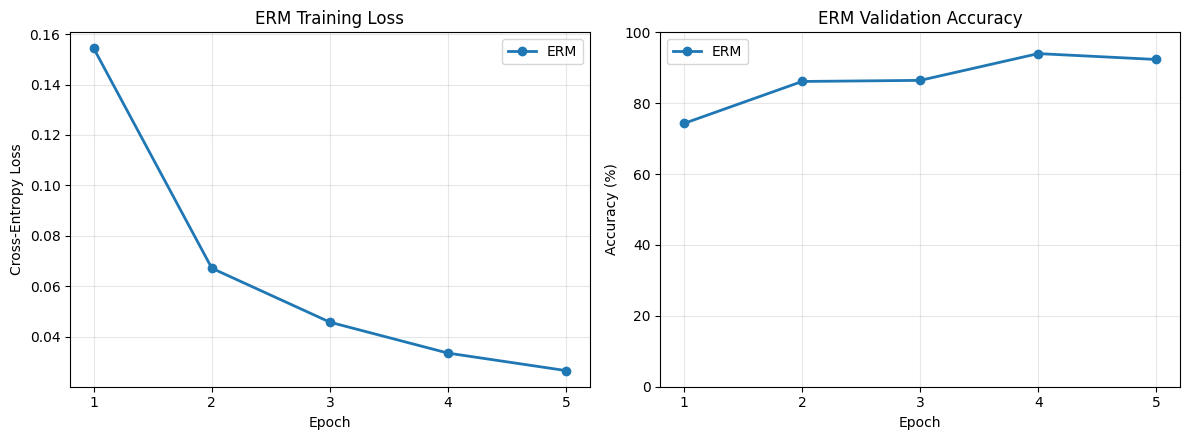

Training curves saved to: results/figures/erm_training_curves.png
Best validation epoch: 4
Best validation accuracy: 94.00%


In [7]:

# ============================================================
# 2.9 Visualize ERM training loss and validation accuracy
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. Prepare experimental results
# ------------------------------------------------------------

epochs = np.arange(1, len(train_losses) + 1)

loss_values = np.asarray(train_losses)
accuracy_values = np.asarray(val_accuracies) * 100

# Create a directory for report-ready figures.
FIGURE_DIR = Path("results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. Plot training curves
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Training loss
axes[0].plot(
    epochs,
    loss_values,
    marker="o",
    linewidth=2,
    label="ERM",
)

axes[0].set_title("ERM Training Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].set_xticks(epochs)
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Validation accuracy
axes[1].plot(
    epochs,
    accuracy_values,
    marker="o",
    linewidth=2,
    label="ERM",
)

axes[1].set_title("ERM Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].set_xticks(epochs)
axes[1].set_ylim(0, 100)
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()

# ------------------------------------------------------------
# 3. Save publication-quality figure
# ------------------------------------------------------------

save_path = FIGURE_DIR / "erm_training_curves.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Training curves saved to: {save_path}")

# ------------------------------------------------------------
# 4. Identify best validation epoch
# ------------------------------------------------------------

best_epoch = int(np.argmax(accuracy_values)) + 1
best_accuracy = float(np.max(accuracy_values))

print(f"Best validation epoch: {best_epoch}")
print(f"Best validation accuracy: {best_accuracy:.2f}%")


### 2.10 Group-Wise Evaluation and Robustness Analysis

We evaluate the trained ERM model separately on the four class–background groups in SpuCoMNIST.

Although overall accuracy measures average classification performance, it may conceal poor performance on minority groups.

We calculate:

- **Average Accuracy:** Percentage of correctly classified examples across the evaluation dataset.
- **Group Accuracy:** Accuracy within each class–background combination.
- **Worst-Group Accuracy (WGA):** The minimum accuracy among all four groups.
- **Accuracy Gap:** The difference between the highest and lowest group accuracies.

**Objective:** Determine whether standard ERM disproportionately underperforms on minority examples that violate the dominant training correlation.

We use both validation and test datasets for this initial baseline analysis. For subsequent model selection, we will use validation metrics and reserve test metrics for final reporting.

In [8]:

# ============================================================
# 2.10 Group-wise accuracy evaluation
# ============================================================

import numpy as np
from torch.utils.data import DataLoader

@torch.no_grad()
def evaluate_groups(model, dataset):
    model.eval()

    loader = DataLoader(
        dataset,
        batch_size=128,
        shuffle=False,
        num_workers=0
    )

    predictions = []
    labels = []

    # Generate predictions in dataset order.
    for images, targets in loader:
        images = images.to(device)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        predictions.extend(preds.cpu().numpy())
        labels.extend(targets.numpy())

    predictions = np.asarray(predictions)
    labels = np.asarray(labels)

    average_accuracy = np.mean(predictions == labels)

    # Calculate accuracy for each group.
    group_accuracies = {}

    for group, indices in sorted(
        dataset.group_partition.items()
    ):
        indices = np.asarray(indices, dtype=int)

        group_accuracies[group] = float(
            np.mean(predictions[indices] == labels[indices])
        )

    worst_group_accuracy = min(group_accuracies.values())
    accuracy_gap = (
        max(group_accuracies.values())
        - worst_group_accuracy
    )

    return {
        "average_accuracy": average_accuracy,
        "group_accuracies": group_accuracies,
        "worst_group_accuracy": worst_group_accuracy,
        "accuracy_gap": accuracy_gap
    }


# Evaluate both splits.
val_results = evaluate_groups(model, val_dataset)
test_results = evaluate_groups(model, test_dataset)

for name, results in [
    ("Validation", val_results),
    ("Test", test_results)
]:
    print(f"\n{'=' * 50}")
    print(f"ERM — {name}")
    print(f"{'=' * 50}")

    print(f"Average Accuracy: {results['average_accuracy']:.2%}")

    for group, acc in results["group_accuracies"].items():
        print(f"Group {group}: {acc:.2%}")

    print(
        f"Worst-Group Accuracy: "
        f"{results['worst_group_accuracy']:.2%}"
    )
    print(f"Accuracy Gap: {results['accuracy_gap']:.2%}")



ERM — Validation
Average Accuracy: 92.34%
Group (0, 0): 99.61%
Group (0, 1): 81.85%
Group (1, 0): 88.27%
Group (1, 1): 99.76%
Worst-Group Accuracy: 81.85%
Accuracy Gap: 17.91%

ERM — Test
Average Accuracy: 92.82%
Group (0, 0): 99.57%
Group (0, 1): 83.11%
Group (1, 0): 89.10%
Group (1, 1): 99.67%
Worst-Group Accuracy: 83.11%
Accuracy Gap: 16.56%


### 2.11 Visualization of Group-Wise Robustness

We compare the classification accuracy of the ERM baseline across all four class–background groups.

The visualization distinguishes majority and minority groups and reports both validation and test accuracy.

Our goal is to determine whether the model's performance depends on the relationship between digit labels and spurious background colors.

A substantial performance gap between majority and minority groups would indicate that standard ERM training does not generalize equally across different class–background combinations.

This figure will serve as a reference for subsequent EPIC, JTT, and random-filtering experiments.

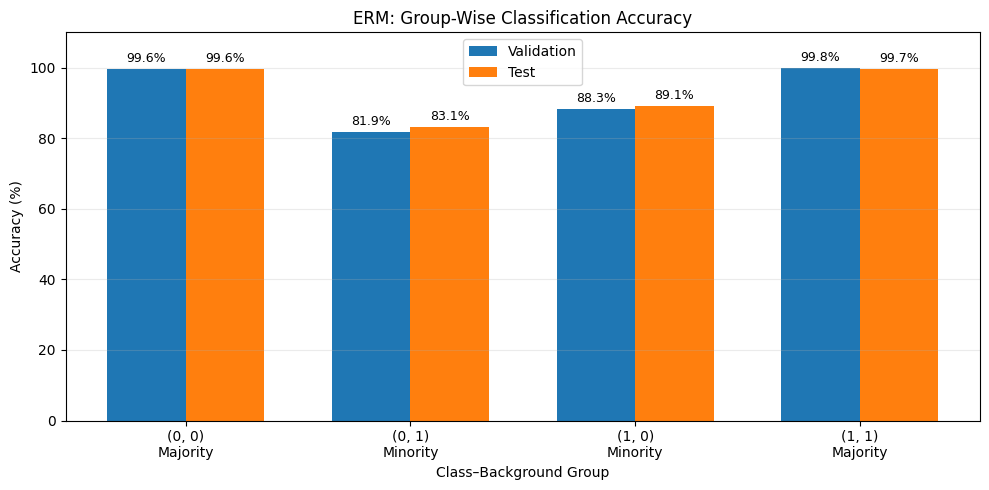

Figure saved to: results/figures/erm_group_accuracy.png


In [9]:

# ============================================================
# 2.11 Visualize group-wise ERM classification accuracy
# ============================================================

from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

groups = sorted(val_results["group_accuracies"].keys())

val_acc = [
    val_results["group_accuracies"][g] * 100
    for g in groups
]

test_acc = [
    test_results["group_accuracies"][g] * 100
    for g in groups
]

group_labels = [
    f"{g}\n{'Majority' if g[0] == g[1] else 'Minority'}"
    for g in groups
]

x = np.arange(len(groups))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))

bars_val = ax.bar(
    x - width / 2,
    val_acc,
    width,
    label="Validation",
)

bars_test = ax.bar(
    x + width / 2,
    test_acc,
    width,
    label="Test",
)

# Display accuracy values above bars.
for bars in [bars_val, bars_test]:
    ax.bar_label(
        bars,
        fmt="%.1f%%",
        padding=3,
        fontsize=9,
    )

ax.set_title("ERM: Group-Wise Classification Accuracy")
ax.set_xlabel("Class–Background Group")
ax.set_ylabel("Accuracy (%)")
ax.set_xticks(x)
ax.set_xticklabels(group_labels)
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

FIGURE_DIR = Path("results/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

save_path = FIGURE_DIR / "erm_group_accuracy.png"

fig.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(f"Figure saved to: {save_path}")


### 2.12 Experimental Results and Discussion

The ERM baseline was trained for five epochs on SpuCoMNIST with a 95% spurious-correlation strength. Training completed in approximately 11 seconds using Apple Silicon GPU acceleration.

**Key Results**

| Metric | Validation | Test |
|---|---:|---:|
| Average accuracy | 92.34% | 92.82% |
| Worst-group accuracy | 81.85% | 83.11% |
| Best-group accuracy | 99.76% | 99.67% |
| Accuracy gap | 17.91 pp | 16.56 pp |

The CNN achieves approximately 99.6% accuracy on both majority groups, while its accuracy on minority groups is substantially lower.

In particular, group (0, 1) achieves the lowest test accuracy at 83.11%, compared with 99.67% for the highest-performing group.

These findings are consistent with the hypothesis that standard ERM training partially exploits the strong background-color correlation rather than relying exclusively on digit features.

However, this experiment does not establish the precise mechanism behind the performance differences. Additional experiments will be required to determine the effect of gradient-based filtering on minority-group preservation.

**Implications for EPIC**

The ERM baseline establishes a measurable robustness gap that subsequent methods can be evaluated against.

Our next experiment will investigate whether EPIC's gradient-space filtering disproportionately removes minority examples and how this influences worst-group accuracy.

This baseline provides a reference for assessing whether a data-filtering strategy improves robustness, maintains accuracy, or unintentionally amplifies existing dataset biases.

In [10]:

# ============================================================
# 2.12 Save ERM baseline model and experimental results
# ============================================================

from pathlib import Path
import json
import torch

# Create output directories.
MODEL_DIR = Path("results/models")
METRIC_DIR = Path("results/metrics")

MODEL_DIR.mkdir(parents=True, exist_ok=True)
METRIC_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Save trained model checkpoint
# ------------------------------------------------------------

checkpoint_path = MODEL_DIR / "erm_baseline.pt"

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "epochs": EPOCHS,
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "seed": SEED,
    },
    checkpoint_path,
)

# ------------------------------------------------------------
# 2. Save experimental metrics as JSON
# ------------------------------------------------------------

metrics = {
    "model": "ERM",
    "dataset": "SpuCoMNIST",
    "spurious_correlation": 0.95,
    "epochs": EPOCHS,
    "training_time_seconds": elapsed_time,
    "train_losses": train_losses,
    "validation_accuracies": val_accuracies,
    "validation": {
        "average_accuracy": val_results["average_accuracy"],
        "worst_group_accuracy": val_results["worst_group_accuracy"],
        "group_accuracies": {
            str(k): v
            for k, v in val_results["group_accuracies"].items()
        },
    },
    "test": {
        "average_accuracy": test_results["average_accuracy"],
        "worst_group_accuracy": test_results["worst_group_accuracy"],
        "group_accuracies": {
            str(k): v
            for k, v in test_results["group_accuracies"].items()
        },
    },
}

metrics_path = METRIC_DIR / "erm_baseline.json"

with open(metrics_path, "w") as f:
    json.dump(metrics, f, indent=4)

print("ERM experiment saved successfully!")
print("Model:", checkpoint_path)
print("Metrics:", metrics_path)


ERM experiment saved successfully!
Model: results/models/erm_baseline.pt
Metrics: results/metrics/erm_baseline.json
